# Day 2 - Supervised learning practical tasks
***
These tasks cover linear regression, logistic regression, decision trees, model evaluation and regularization.

## Regression models

You will use [Advertising](https://www.kaggle.com/purbar/advertising-data) Dataset. The dataset contains statistics about the sales of a product in 200 different markets, together with advertising budgets in each of these markets for different media channels: TV, radio and newspaper.
#### Your task will be to:
1. Write evaluation functions (MAE, MSE, SSE, RMSE, MAPE, R2).
2. Analyze the correlation matrix.
3. Predict sales values using linear regression.
4. Evaluate model with written statistical explanatory variables.
5. Perform cross-validation (k-fold).
6. Compare your regression model to a reduced model by removing one of the features.
7. Compare your regression model to regularization models.

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

In [307]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet, LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, RocCurveDisplay, roc_curve, auc
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_score

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier

### 1. Create statistical evaluation functions for regression models

#### 1.1 Create a function that calculates mean absolute error (MAE)

\begin{equation}
MAE = \frac{1}{n} \sum_{i=1}^{n} \left| y_i - \hat{y}_i\right|
\end{equation}

In [308]:
# Loading data frame
advertising_data = pd.read_csv('advertising.csv', index_col=0)
# Splitting data features and variables
X = advertising_data.drop('Sales', axis=1)
y = advertising_data['Sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create object that stands for Linear regression
model = LinearRegression(fit_intercept=True)
# Fit linear regression model
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(y_pred)

[16.4080242  20.88988209 21.55384318 10.60850256 22.11237326 13.10559172
 21.05719192  7.46101034 13.60634581 15.15506967  9.04831992  6.65328312
 14.34554487  8.90349333  9.68959028 12.16494386  8.73628397 16.26507258
 10.27759582 18.83109103 19.56036653 13.25103464 12.33620695 21.30695132
  7.82740305  5.80957448 20.75753231 11.98138077  9.18349576  8.5066991
 12.46646769 10.00337695 21.3876709  12.24966368 18.26661538 20.13766267
 14.05514005 20.85411186 11.0174441   4.56899622]


In [309]:
def mae(actual, predicted):
    return np.mean(np.abs(actual - predicted))


print(f"my_own_function: {mae(y_test, y_pred)}")
print(f"sklearn_function: {mean_absolute_error(y_test, y_pred)}")

my_own_function: 1.4607567168117603
sklearn_function: 1.4607567168117603


#### 1.2 Create a function that calculates mean squared error (MSE)

\begin{equation}
MSE = \frac{1}{n}\cdot SSE
\end{equation}

\begin{equation}
SSE = \sum_{i=1}^n(y_i - \hat{y}_i)^2
\end{equation}

In [310]:
def mse(actual, predicted):
    return np.mean((actual - predicted) ** 2)

print(f"my_own_function: {mse(y_test, y_pred)}")
print(f"sklearn_function: {mean_squared_error(y_test, y_pred)}")


my_own_function: 3.1740973539761033
sklearn_function: 3.1740973539761033


#### 1.3 Create a function that calculates root mean squared error (RMSE)

\begin{equation}
RMSE = \sqrt{MSE}
\end{equation}

In [311]:
mse_val = mse(y_test, y_pred)
def rsme(mse_val):
    return np.sqrt(mse_val)

print(f"my_own_function: {rsme(mse_val)}")
print(f"sklearn_function: {np.sqrt(mean_squared_error(y_test, y_pred))}")

my_own_function: 1.78159966153345
sklearn_function: 1.78159966153345


#### 1.4 Create a function that calculates mean absolute percentage error (MAPE)

\begin{equation}
MAPE = \frac{100}{n} \sum_{i=1}^n \left| \frac{y_i - \hat{y}_i}{y_i} \right|
\end{equation}

In [312]:
def mape(actual,predicted):
    return np.mean(np.abs((actual-predicted)/actual))*100

print(mape(y_test, y_pred))

15.198846602831226


#### 1.5 Create a function that calculates coefficient of determination $R^2$ using formula

\begin{equation}
R^2 = \frac{SST-SSE}{SST}
\end{equation}

\begin{equation}
SST = \sum_{i=1}^n (y_i - \bar{y})^2
\end{equation}


In [313]:
def r_square(actual, predicted):
    sst = np.sum((actual - np.mean(actual)) ** 2)
    sse = np.sum((actual - predicted) ** 2)
    return (sst - sse) / sst

print(f"my_own_function: {r_square(y_test, y_pred)}")
print(f"sklearn_function: {r2_score(y_test, y_pred)}")    

my_own_function: 0.899438024100912
sklearn_function: 0.899438024100912


### 2 Use Linear regression model to make predictions and evaluate it with above developed functions. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling - split the data in target variable and features.

In [314]:
# Loading data frame
# using advertising data because the final answer is continues number
advertising_data = pd.read_csv('advertising.csv',index_col=0)

In [315]:
advertising_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 1 to 200
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [316]:
advertising_data.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

In [317]:
cor_mat = advertising_data.corr()
cor_mat

,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.782224
Radio,0.054809,1.000000,0.354104,0.576223
Newspaper,0.056648,0.354104,1.000000,0.228299
Sales,0.782224,0.576223,0.228299,1.000000


<Axes: >

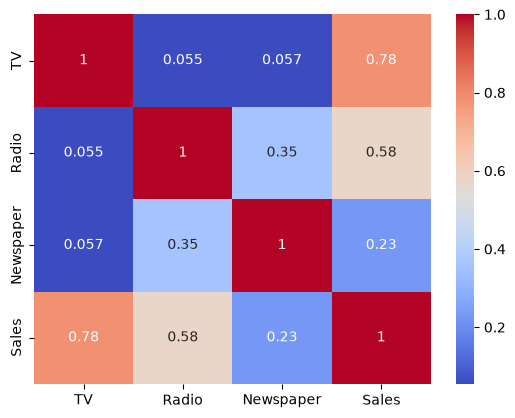

In [318]:
sns.heatmap(cor_mat, annot=True, cmap='coolwarm')

### Observation:

* Look likr TV have more impact on the sales and next is Radio
* Newspaper having weekest corelation with sales not impacting much.

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler).

In [319]:
X = advertising_data.drop('Sales', axis=1)
y = advertising_data['Sales']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=17)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  
X_test_scaled = scaler.transform(X_test)

(134, 3) (134,) (66, 3) (66,)


#### 2.4 Fit linear regression model, generate predictions and print regression coefficients $b_0$ and $b_1$.

In [320]:
model = LinearRegression(fit_intercept=True)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)


In [321]:
print(model.intercept_) # b0
print(model.coef_) # b1

14.022388059701495
[ 3.9675339   2.88155345 -0.07344038]


#### 2.5 Evaluate created model with above functions

In [322]:
# Calculate MAE, MSE, R^2 and RMSE
print("MAE score:", mean_absolute_error(y_test, y_pred))
print("MSE score:", mean_squared_error(y_test, y_pred))
print("RMSE score:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R^2 score:", r2_score(y_test, y_pred))

# Observation:
# Model seems to be performing well as the R^2 score is close to 1 and the MAE, MSE, and RMSE scores are relatively low

MAE score: 1.241490259650847
MSE score: 3.47262996875279
RMSE score: 1.8634993879131783
R^2 score: 0.8515370160992792


#### 2.6 Perform k-fold cross-validation $(k=10)$ and print the mean $R^2$ score to get an overall performance metric.

Please use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [r2](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules) score.

In [323]:

# Data split for k-fold cv
# Number of folds
k = 10
# Initialize KFold
kf = KFold(n_splits=k, shuffle=True, random_state=17)

scores = cross_val_score(model, X, y, cv=kf, scoring='r2')

print(f'mean r2:{np.mean(scores)}')



mean r2:0.877112599900056


#### 2.7. Drop one of the three variables (TV, Radio or Newspaper) and create another model, evaluate it and compare to the first model.

In [324]:
# droping newspaper due to low correlation found with sales , thinking this may improve performance.

new_X = X.drop('Newspaper', axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    new_X, y, test_size=0.33, random_state=17)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  
X_test_scaled = scaler.transform(X_test)

(134, 2) (134,) (66, 2) (66,)


In [325]:
model_2 = LinearRegression(fit_intercept=True)
model_2.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[3.96,2.86]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,14.02
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](2,)","[12.22,10.9 ]"


In [326]:
y_pred = model_2.predict(X_test_scaled)

print("MAE score:", mean_absolute_error(y_test, y_pred))
print("MSE score:", mean_squared_error(y_test, y_pred))
print("RMSE score:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R^2 score:", r2_score(y_test, y_pred))


# Model perfomance is perfomaing almost the same as the previous model, so dropping newspaper did not improve the model performance it seems

MAE score: 1.2423619953941778
MSE score: 3.458740998763223
RMSE score: 1.859769071353544
R^2 score: 0.8521308017736854


### 3. Use regularization models with regularization strength `alpha=1` and compare $MSE$ values with previous models.

#### 3.1 Lasso regression

In [327]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=17)  

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lasso = Lasso(alpha=1.0)
lasso.fit(X_train_scaled, y_train)

y_pred = lasso.predict(X_test_scaled)

mse_lasso = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {mse_lasso}")
print("Coefficients:", lasso.coef_)

Mean Squared Error: 4.911579294712751
Coefficients: [3.0619592  1.96202634 0.        ]


#### 3.2 Ridge regression

In [328]:
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)
y_pred = ridge.predict(X_test_scaled)

mse_ridge = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {mse_ridge}")
print("Coefficients:", ridge.coef_)

Mean Squared Error: 3.4768894774722394
Coefficients: [ 3.93899368  2.85996406 -0.06218255]


#### 3.3 Elastic net regression

Use any `l1_ratio` of your choice.


In [329]:
elastic_net = ElasticNet(alpha=1.0, l1_ratio=0.4)
elastic_net.fit(X_train_scaled, y_train)

y_pred = elastic_net.predict(X_test_scaled)
mse_elastic_net = mean_squared_error(y_test, y_pred)

print(f"Mean Squared Error: {mse_elastic_net}")
print("Coefficients:", elastic_net.coef_)

Mean Squared Error: 7.143519772276349
Coefficients: [2.30344631 1.63694628 0.09468248]


#### 3.4 Make conclusions

Regualrization also proven the newspaper feature seems to be somewhat useless in terms of feautre selection, However removing that feature from the model doesnt improved the model performance the mse value remains almost same for every model difference is arount 0.01 only. Also able to see that TV feature having more impact on the sales.

## Classification models

You will use [Diabetes](https://www.kaggle.com/uciml/pima-indians-diabetes-database) dataset. The dataset includes data from 768 women with several medical predictor variables and one target variable. The classification goal is to predict whether or not the patients in the dataset have diabetes.
#### Your task will be to:
1. Write evaluation functions (Accuracy, Precision, Recall, F1).
2. Predict whether or not a patient has diabetes using Logistic regression and Decision Tree Classification models
3. Evaluate both models with written statistical explanatory variables
4. Draw ROC curve and compute AUC
5. Perform cross-validation (k-fold)
6. Analyze the results

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

### 1. Write statistical evaluation functions for classification models

#### 1.1 Create a function that calculates accuracy

\begin{equation}
Accuracy = \frac{True Positive + True Negative}{True Positive + True Negative + False Positive + False Negative}
\end{equation}

In [330]:
def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)

#### 1.2 Create a function that calculates precision

\begin{equation}
Precision = \frac{True Positive}{True Positive + False Positive}
\end{equation}

In [331]:
def precision(actual, predicted):
    true_positive = np.sum((actual == 1) & (predicted == 1))
    false_positive = np.sum((actual == 0) & (predicted == 1))
    return true_positive / (true_positive + false_positive)

#### 1.3  Create a function that calculates recall

\begin{equation}
Recall = \frac{True Positive}{True Positive + False Negative}
\end{equation}

In [332]:
def recall(actual, predicted):
    true_positive = np.sum((actual == 1) & (predicted == 1))
    false_negative = np.sum((actual == 1) & (predicted == 0))
    return true_positive / (true_positive + false_negative)

#### 1.4 Create a function that calculates $F1$ - score

\begin{equation}
F1 = 2\cdot \frac{Precision \cdot Recall}{Precision + Recall}
\end{equation}

In [333]:
def F1_score(actual, predicted):
    prec = precision(actual, predicted)
    rec = recall(actual, predicted)
    return 2 * (prec * rec) / (prec + rec)

### 2. Use logistic regression to make prediction and evaluate it with above developed functions. Compute ROC and compute AUC. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling. Split the data in target variable and features.

Prepare dataset to use it for modelling (you should also replace 0 values in columns `Glucose`, `BloodPressure`,`SkinThickness`,`Insulin`,`BMI` with mean values).

In [334]:
diabetes_data = pd.read_csv('diabetes.csv')

diabetes_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [335]:
columns_with_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

# Replacing 0 directly wtih mean first calulate the mean including 0 therefore first replace it with null so this iwll be reomved and then we can fill up with mean value of the column
for c in columns_with_zero:
    diabetes_data[c] = diabetes_data[c].replace(0,np.nan)
    diabetes_data[c] = diabetes_data[c].fillna(np.mean(diabetes_data[c]))

diabetes_data[diabetes_data['Glucose'] == 0].value_counts()


Series([], Name: count, dtype: int64)

#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

<Axes: >

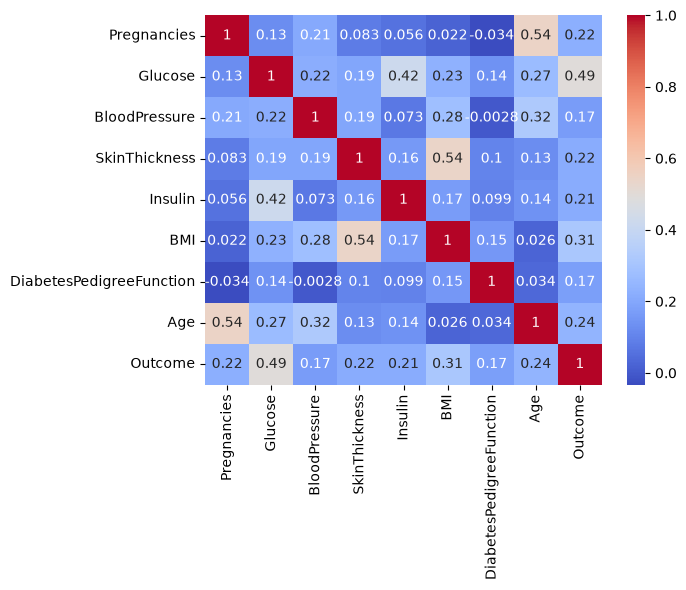

In [336]:
cor_mat = diabetes_data.corr()

sns.heatmap(cor_mat, annot=True, cmap='coolwarm')

# Observation:
# outcome has good correlation with glucose followed by BMI and age we should have to keep that, However nothing proves a strong relatoin

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

In [337]:
X = diabetes_data.drop('Outcome', axis=1)
y = diabetes_data['Outcome']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=17)

scalar = StandardScaler()
X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.transform(X_test)

#### 2.4 Fit logistic regression model, generate predictions

In [338]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

y_pred_log = model.predict(X_test_scaled)

#### 2.5 Create a confusion matrix and evaluate created model with above functions

In [339]:
# Calculate the confusion matrix
cnf_matrix = confusion_matrix(y_test, y_pred_log)
cnf_matrix

array([[145,  20],
       [ 43,  46]])

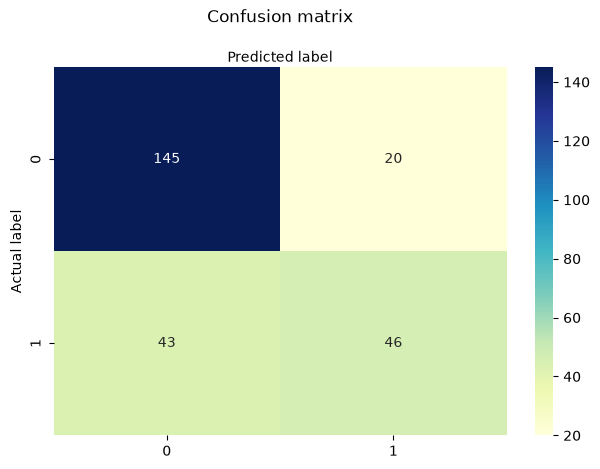

In [340]:
class_names = [0, 1] # names of classes
fig, ax = plt.subplots()
# Create heatmap (seaborn places the tick labels in the centre of each cell)
sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu", fmt='g',
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.xaxis.set_label_position("top")
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.tight_layout()
plt.show()

#### 2.6 Draw a ROC curve and compute Area Under the Curve (AUC)

You can use [roc_auc_score](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html) and [RocCurveDisplay.from_predictions](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html#sklearn.metrics.RocCurveDisplay.from_predictions).
Check documentation for examples.
For roc_auc_score use predicted probabilities (`predict_proba`), not predicted values. This will align your AUC and ROC curve values.

`predict_proba()` method returns a two-dimensional array. For each instance the predicted class is the class with the maximum probability. To calculate AUC correctly, you need the probability of the positive class (second column, `[:, 1]`).

In [341]:
y_pred_prob = model.predict_proba(X_test_scaled)[:, 1]
roc_score = roc_curve(y_test, y_pred_prob)
print(f"ROC AUC score: {auc(roc_score[0], roc_score[1])}")

ROC AUC score: 0.8311201906707525


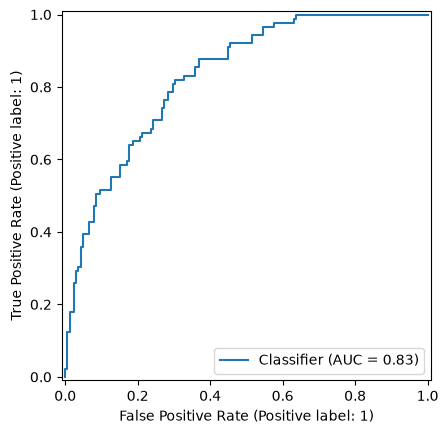

In [342]:
RocCurveDisplay.from_predictions(y_test, y_pred_prob)

#### 2.7 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

Use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [accuracy](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules). Feed your scaled X train and y train data.

In [343]:
k = 10

kf = KFold(n_splits=k, shuffle=True, random_state=17)

scores = cross_val_score(model, X, y, cv=kf, scoring='accuracy')

print(f'mean accuracy:{np.mean(scores)}')

mean accuracy:0.7722146274777855


### 3. Use Decision tree classification model to make predictions and evaluate it with above developed functions. Draw ROC curve and compute AUC. Perform k-fold cross-validation.

#### 3.1 Create classification tree object, fit model and generate predictions

In [344]:
clf = DecisionTreeClassifier(random_state=17)
clf.fit(X_train_scaled, y_train)

y_pred_tree = clf.predict(X_test_scaled)

#### 3.2 Evaluate created model with above functions

In [345]:
print(f"Accuracy: {accuracy(y_test, y_pred_tree)}")
print(f"Precision: {precision(y_test, y_pred_tree)}")
print(f"Recall: {recall(y_test, y_pred_tree)}")
print(f"F1-Score: {F1_score(y_test, y_pred_tree)}")

Accuracy: 0.7755905511811023
Precision: 0.6666666666666666
Recall: 0.7191011235955056
F1-Score: 0.6918918918918919


#### 3.3 Draw a ROC curve and compute Area Under the Curve (AUC)

In [346]:
y_pred_prob_clf = clf.predict_proba(X_test_scaled)[:, 1]
roc_score_tree = roc_curve(y_test, y_pred_prob_clf)
print(f"ROC AUC score: {auc(roc_score_tree[0], roc_score_tree[1])}")

ROC AUC score: 0.7625808648280558


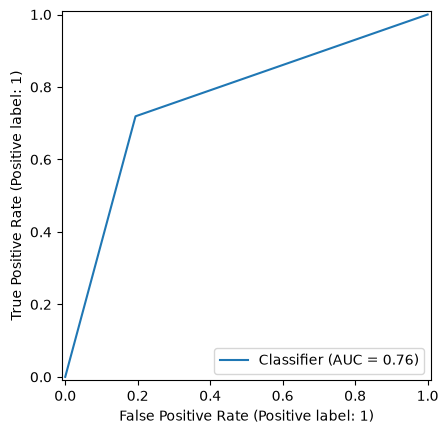

In [347]:
RocCurveDisplay.from_predictions(y_test, y_pred_prob_clf)

#### 3.4 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

In [348]:
k = 10

kf = KFold(n_splits=k, shuffle=True, random_state=17)

scores = cross_val_score(clf, X, y, cv=kf, scoring='accuracy')

print(f'mean accuracy:{np.mean(scores)}')

mean accuracy:0.7082877648667122


#### 3.5 Make conclusions

In this case the Logestic regression model show good accuracy and the decision tree have low accuray than that, Also, When checking the 